# Uncertainty Bucketing: Where Optimal Transport (OT) Helps

This notebook buckets anchors by **baseline confidence** using the margin:

**margin = top1_score − top2_score** (higher margin = more confident)

For each bucket (Q1–Q5), it evaluates **Recall@K** using GroupKFold (group = `anchor_id`) for:
- Baseline only (DTW or Centroid)
- Baseline + OT
- Baseline + Centroid
- Baseline + OT + Centroid


In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore")

# Jupyter-friendly: do NOT force Agg; show figures inline and still save to PDF.
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.linewidth": 0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

WINDOW_SIZE = 200

In [2]:
from cell_matching_utils import (
    load_cells_from_csv_files,
    dtw_distance_gpu_single,
    get_cluster_cells,
    compute_ot_cost_matrix,
    solve_optimal_transport,
    DTW_NORM_DIVISOR,
    OT_NORM_DIVISOR,
    CENTROID_NORM_DIVISOR,
    NUM_CONTOUR_POINTS,
)

In [3]:
def uniform_resample_contour(contour: np.ndarray, n: int) -> np.ndarray:
    contour = np.asarray(contour)
    if contour.shape[0] == n:
        return contour
    if not np.allclose(contour[0], contour[-1]):
        contour = np.vstack([contour, contour[:1]])
    seg = np.diff(contour, axis=0)
    d = np.sqrt((seg**2).sum(axis=1))
    s = np.concatenate([[0.0], np.cumsum(d)])
    L = float(s[-1])
    if L == 0.0:
        return np.tile(contour[0], (n, 1))
    st = np.linspace(0.0, L, n)
    x = np.interp(st, s, contour[:, 0])
    y = np.interp(st, s, contour[:, 1])
    return np.c_[x, y]


def candidates_in_window(anchor, candidates, window: float):
    half = window / 2.0
    ax, ay = anchor.centroid
    out = []
    for c in candidates:
        cx, cy = c.centroid
        if abs(cx - ax) <= half and abs(cy - ay) <= half:
            out.append(c)
    return out


def pair_features(cell1, cell2, cells_by_slice) -> dict:
    feats = {}

    # DTW similarity in [0, 10] (higher is better)
    try:
        if hasattr(cell1, "contour_points_200") and hasattr(cell2, "contour_points_200"):
            dtw_raw = dtw_distance_gpu_single(cell1.contour_points_200, cell2.contour_points_200)
        else:
            c1 = uniform_resample_contour(cell1.contour_points, NUM_CONTOUR_POINTS)
            c2 = uniform_resample_contour(cell2.contour_points, NUM_CONTOUR_POINTS)
            dtw_raw = dtw_distance_gpu_single(c1, c2)
        dtw_loss = min(10.0, (dtw_raw / DTW_NORM_DIVISOR) * 10.0)
        feats["dtw_similarity"] = 10.0 - dtw_loss
    except Exception:
        feats["dtw_similarity"] = 0.0

    # OT similarity in [0, 10]
    try:
        cl1 = get_cluster_cells(cell1, cells_by_slice)
        cl2 = get_cluster_cells(cell2, cells_by_slice)
        if len(cl1) == 1 and len(cl2) == 1:
            feats["ot_similarity"] = 10.0
        elif len(cl1) > 1 and len(cl2) > 1:
            C = compute_ot_cost_matrix(cl1, cl2)
            a1 = np.array([c.area for c in cl1], dtype=float)
            a2 = np.array([c.area for c in cl2], dtype=float)
            w1 = a1 / a1.sum()
            w2 = a2 / a2.sum()
            ot_raw, _ = solve_optimal_transport(C, w1, w2)
            ot_loss = min(10.0, (ot_raw / OT_NORM_DIVISOR) * 10.0)
            feats["ot_similarity"] = 10.0 - ot_loss
        else:
            feats["ot_similarity"] = 0.0
    except Exception:
        feats["ot_similarity"] = 0.0

    # Centroid similarity in [0, 10]
    x1, y1 = cell1.centroid
    x2, y2 = cell2.centroid
    dist = float(np.hypot(x2 - x1, y2 - y1))
    loss = min(10.0, (dist / CENTROID_NORM_DIVISOR) * 10.0)
    feats["centroid_similarity"] = 10.0 - loss

    return feats

In [4]:
def build_dataset(golden_df: pd.DataFrame, cells_by_slice: dict) -> pd.DataFrame:
    rows = []
    for _, r in golden_df.iterrows():
        sL, eL = int(r["Start_layer"]), int(r["End_layer"])
        if eL - sL != 1:
            continue

        start_id = r["Start_cell"]
        true_id = r["End_cell"]

        anchor = next((c for c in cells_by_slice.get(sL, []) if c.cell_id == start_id), None)
        if anchor is None:
            continue

        cand = candidates_in_window(anchor, cells_by_slice.get(eL, []), WINDOW_SIZE)
        if not cand:
            continue

        anchor_id = f"L{sL}_{start_id}"
        for c in cand:
            rows.append({
                "anchor_id": anchor_id,
                "start_layer": sL,
                "end_layer": eL,
                "start_cell_id": start_id,
                "candidate_cell_id": c.cell_id,
                "is_true_match": (c.cell_id == true_id),
                **pair_features(anchor, c, cells_by_slice),
            })

    df = pd.DataFrame(rows)
    if df.empty:
        raise RuntimeError("Empty dataset: check input files, slice IDs, and WINDOW_SIZE.")
    return df

In [5]:
def oof_predict(df: pd.DataFrame, features: list[str]) -> np.ndarray:
    X = df[features].to_numpy(float)
    y = df["is_true_match"].to_numpy(int)
    groups = df["anchor_id"].to_numpy()

    X = StandardScaler().fit_transform(X)
    clf = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")

    pred = np.zeros(len(df), float)
    for tr, va in GroupKFold(n_splits=5).split(X, y, groups=groups):
        clf.fit(X[tr], y[tr])
        pred[va] = clf.predict_proba(X[va])[:, 1]
    return pred


def anchor_margins(df: pd.DataFrame, feature: str) -> dict:
    out = {}
    for aid in df["anchor_id"].unique():
        s = df.loc[df["anchor_id"] == aid, feature].to_numpy(float)
        if s.size < 2:
            out[aid] = np.nan
            continue
        s = np.sort(s)[::-1]
        out[aid] = float(s[0] - s[1])
    return out


def quantile_buckets(margins: dict, q: int = 5):
    valid = {k: v for k, v in margins.items() if not np.isnan(v)}
    vals = np.array(list(valid.values()), float)
    edges = np.quantile(vals, np.linspace(0, 1, q + 1))
    a2b = {k: int(np.searchsorted(edges[1:-1], v, side="right")) for k, v in valid.items()}
    ranges = [(float(edges[i]), float(edges[i+1])) for i in range(q)]
    return a2b, ranges


def bucket_metrics(df: pd.DataFrame, a2b: dict, features: list[str], bucket_id: int):
    anchors = [a for a, b in a2b.items() if b == bucket_id]
    if not anchors:
        return None
    d = df[df["anchor_id"].isin(anchors)].copy()
    if d.empty:
        return None

    score = oof_predict(d, features)
    y = d["is_true_match"].to_numpy(int)
    aid = d["anchor_id"].to_numpy()

    r1 = r3 = r5 = 0
    ranks = []
    n = 0

    for a in anchors:
        m = (aid == a)
        if y[m].sum() == 0:
            continue
        n += 1
        order = np.argsort(score[m])[::-1]
        lab = y[m]
        r1 += int(lab[order[:1]].sum() > 0)
        r3 += int(lab[order[:3]].sum() > 0)
        r5 += int(lab[order[:5]].sum() > 0)
        true_pos = np.where(lab == 1)[0][0]
        ranks.append(int(np.where(order == true_pos)[0][0] + 1))

    if n == 0:
        return None
    return {
        "num_anchors": n,
        "Recall@1": r1 / n,
        "Recall@3": r3 / n,
        "Recall@5": r5 / n,
        "mean_rank": float(np.mean(ranks)),
    }

In [6]:
def run_uncertainty_analysis(df: pd.DataFrame, base_feature: str, base_name: str, buckets: int = 5):
    m = anchor_margins(df, base_feature)
    a2b, ranges = quantile_buckets(m, q=buckets)

    configs = [
        ([base_feature], base_name),
        ([base_feature, "ot_similarity"], f"{base_name}+OT"),
        ([base_feature, "centroid_similarity"], f"{base_name}+Centroid"),
        ([base_feature, "ot_similarity", "centroid_similarity"], f"{base_name}+OT+Centroid"),
    ]

    rows = []
    for bid in range(buckets):
        bmin, bmax = ranges[bid]
        for feats, label in configs:
            met = bucket_metrics(df, a2b, feats, bid)
            if met is None:
                continue
            rows.append({
                "bucket_id": bid,
                "bucket_min": bmin,
                "bucket_max": bmax,
                "config": label,
                **met,
            })

    return pd.DataFrame(rows), a2b, ranges

In [7]:
def plot_ot_gains(dtw_res: pd.DataFrame, cen_res: pd.DataFrame, outdir: str):
    def _gain(res, base, with_ot):
        b = res[res["config"] == base].sort_values("bucket_id")
        o = res[res["config"] == with_ot].sort_values("bucket_id")
        if b.empty or o.empty:
            return None, None
        x = b["bucket_id"].to_numpy(int)
        g = (o["Recall@1"].to_numpy(float) - b["Recall@1"].to_numpy(float)) * 100.0
        return x, g

    fig, ax = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)

    for j, (res, base, ot, title) in enumerate([
        (dtw_res, "DTW", "DTW+OT", "OT gain over DTW"),
        (cen_res, "Centroid", "Centroid+OT", "OT gain over Centroid"),
    ]):
        x, g = _gain(res, base, ot)
        if x is None:
            ax[j].set_axis_off()
            continue
        bars = ax[j].bar(x, g, color="#F18F01", edgecolor="black", linewidth=0.7, alpha=0.85)
        for i, v in enumerate(g):
            if v > 2:
                bars[i].set_edgecolor("#D62246")
                bars[i].set_linewidth(1.5)
            ax[j].text(i, v + (0.5 if v >= 0 else -0.5), f"{v:+.1f}%",
                       ha="center", va="bottom" if v >= 0 else "top", fontsize=7)

        ax[j].axhline(0, color="gray", ls="--", lw=1)
        ax[j].set_xticks(x, [f"Q{k+1}" for k in x], fontsize=8)
        ax[j].set_xlabel("Uncertainty buckets (Q1 = least confident, Q5 = most confident)", fontsize=8)
        ax[j].set_ylabel("Recall@1 gain (%)", fontsize=8)
        ax[j].set_title(title, fontsize=9)
        ax[j].grid(True, axis="y", alpha=0.3, lw=0.5)

    pdf = os.path.join(outdir, "ot_gains_combined.pdf")
    fig.savefig(pdf, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {pdf}")

Loading from cell-002_processed: found 15 CSV files


Loading CSV files: 100%|██████████| 15/15 [01:17<00:00,  5.19s/it]



Total cells loaded: 12009


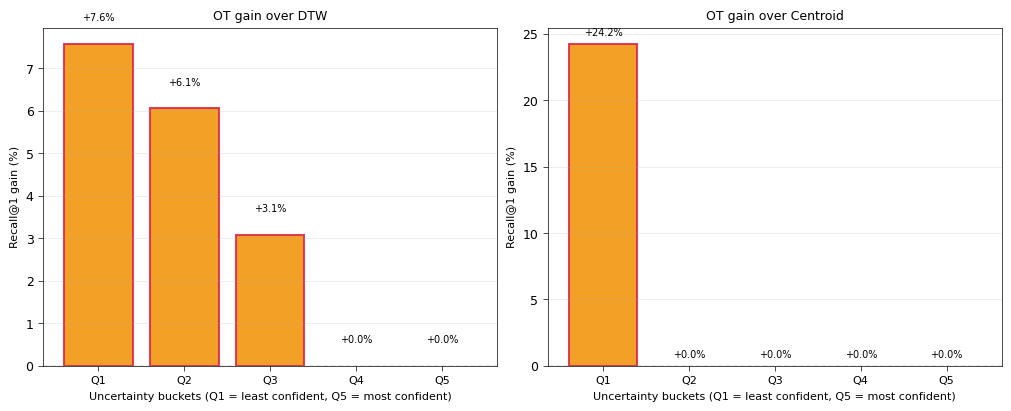

Saved: uncertainty_bucketing_analysis/ot_gains_combined.pdf


,bucket_id,bucket_min,bucket_max,config,num_anchors,Recall@1,Recall@3,Recall@5,mean_rank
0,0,0.000000,0.198287,DTW,66,0.318182,0.636364,0.803030,4.136364
1,0,0.000000,0.198287,DTW+OT,66,0.393939,0.696970,0.833333,3.696970
2,0,0.000000,0.198287,DTW+Centroid,66,0.818182,0.939394,0.984848,1.454545
3,0,0.000000,0.198287,DTW+OT+Centroid,66,0.848485,0.939394,0.984848,1.393939
4,1,0.198287,0.397119,DTW,66,0.303030,0.727273,0.893939,3.015152
5,1,0.198287,0.397119,DTW+OT,66,0.363636,0.712121,0.924242,2.803030
6,1,0.198287,0.397119,DTW+Centroid,66,0.818182,0.954545,0.954545,1.393939
7,1,0.198287,0.397119,DTW+OT+Centroid,66,0.878788,0.954545,0.984848,1.287879
8,2,0.397119,0.780949,DTW,65,0.553846,0.738462,0.830769,2.892308
9,2,0.397119,0.780949,DTW+OT,65,0.584615,0.800000,0.907692,2.476923


,bucket_id,bucket_min,bucket_max,config,num_anchors,Recall@1,Recall@3,Recall@5,mean_rank
0,0,0.001684,0.608414,Centroid,66,0.378788,0.878788,0.909091,2.560606
1,0,0.001684,0.608414,Centroid+OT,66,0.621212,0.878788,0.893939,2.000000
2,0,0.001684,0.608414,Centroid+Centroid,66,0.378788,0.878788,0.909091,2.560606
3,0,0.001684,0.608414,Centroid+OT+Centroid,66,0.621212,0.878788,0.893939,2.000000
4,1,0.608414,1.418847,Centroid,65,0.676923,0.923077,0.953846,1.676923
5,1,0.608414,1.418847,Centroid+OT,65,0.676923,0.938462,0.969231,1.584615
6,1,0.608414,1.418847,Centroid+Centroid,65,0.676923,0.923077,0.953846,1.676923
7,1,0.608414,1.418847,Centroid+OT+Centroid,65,0.676923,0.938462,0.969231,1.584615
8,2,1.418847,2.416917,Centroid,67,0.716418,0.940299,0.955224,1.761194
9,2,1.418847,2.416917,Centroid+OT,67,0.716418,0.940299,0.955224,1.641791


In [8]:
# Inputs
golden_csv = "High_confidence_pairing_4nums_fullnames.csv"
cells_dir = "cell-002_processed"
outdir = "uncertainty_bucketing_analysis"
os.makedirs(outdir, exist_ok=True)

# Load
golden_df = pd.read_csv(golden_csv)
cells_by_slice = load_cells_from_csv_files(cells_dir)

# Dataset
df = build_dataset(golden_df, cells_by_slice)
df.to_csv(os.path.join(outdir, "dataset_dtw_ot_centroid.csv"), index=False)

# Analyses
dtw_res, _, _ = run_uncertainty_analysis(df, "dtw_similarity", "DTW", buckets=5)
cen_res, _, _ = run_uncertainty_analysis(df, "centroid_similarity", "Centroid", buckets=5)

dtw_res.to_csv(os.path.join(outdir, "dtw_uncertainty_results.csv"), index=False)
cen_res.to_csv(os.path.join(outdir, "centroid_uncertainty_results.csv"), index=False)

# Plot (save + display)
plot_ot_gains(dtw_res, cen_res, outdir)

# Quick peek
display(dtw_res.head(10))
display(cen_res.head(10))